# Problema 4 — Outliers (Valores atípicos)
## Dataset: Base 2 — Matrícula y secciones 2023

**Qué vamos a aprender:**
1. Cómo los outliers distorsionan MSE/RMSE pero no MAE
2. Por qué el ratio RMSE/MAE es el indicador clave
3. Cómo detectarlos (IQR, Z-score, Isolation Forest)
4. Cómo decidir si eliminarlos o preservarlos

### Nuestro contexto
El dataset de escuelas tiene outliers **reales** y **legítimos**: escuelas enormes (miles de alumnos)
conviviendo con escuelas diminutas (10-20 alumnos). La distribución es altamente asimétrica.

## 0. Setup y carga

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, HuberRegressor
from sklearn.ensemble import RandomForestRegressor, IsolationForest
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

np.random.seed(42)
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (11, 5)

ARCHIVO = 'data/matricula_secciones_2023.csv'
df_raw = pd.read_csv(ARCHIVO, sep=';', encoding='utf-8-sig', low_memory=False)

mat_cols = [c for c in ['_1','_2','_3','_4','_5','_6','_7','_8','_9','_10','_11','_12','_1314','_snu'] if c in df_raw.columns]
rep_cols = [c for c in ['r_1','r_2','r_3','r_4','r_5','r_6','r_7','r_8','r_9','r_10','r_11','r_12','r_1314','r_20'] if c in df_raw.columns]
sec_cols = [c for c in ['_sec1','_sec2','_sec3','_sec4','_sec5','_sec6','_sec7','_sec8','_sec9','_sec10','_sec11','_sec12','_sec1314','_sec20'] if c in df_raw.columns]

df = df_raw.copy()
df['matricula_total']   = df[mat_cols].apply(pd.to_numeric, errors='coerce').sum(axis=1, min_count=1)
df['repetidores_total'] = df[rep_cols].apply(pd.to_numeric, errors='coerce').sum(axis=1, min_count=1)
df['secciones_total']   = df[sec_cols].apply(pd.to_numeric, errors='coerce').sum(axis=1, min_count=1)
df = df[df['matricula_total'] > 0].dropna(subset=['secciones_total']).copy()

print(f'Escuelas: {len(df):,}')

Escuelas: 37,582


## 1. Dónde están los outliers — inspección visual

Matrícula total por escuela:
count    37582.0
mean       262.4
std        306.1
min          1.0
1%           2.0
25%         40.0
50%        181.0
75%        381.0
95%        767.9
99%       1259.2
99.9%     2664.4
max       9464.0
Name: matricula_total, dtype: float64


/tmp/ipykernel_325/1747091933.py:20: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes[1,0].boxplot(df['matricula_total'], vert=False)


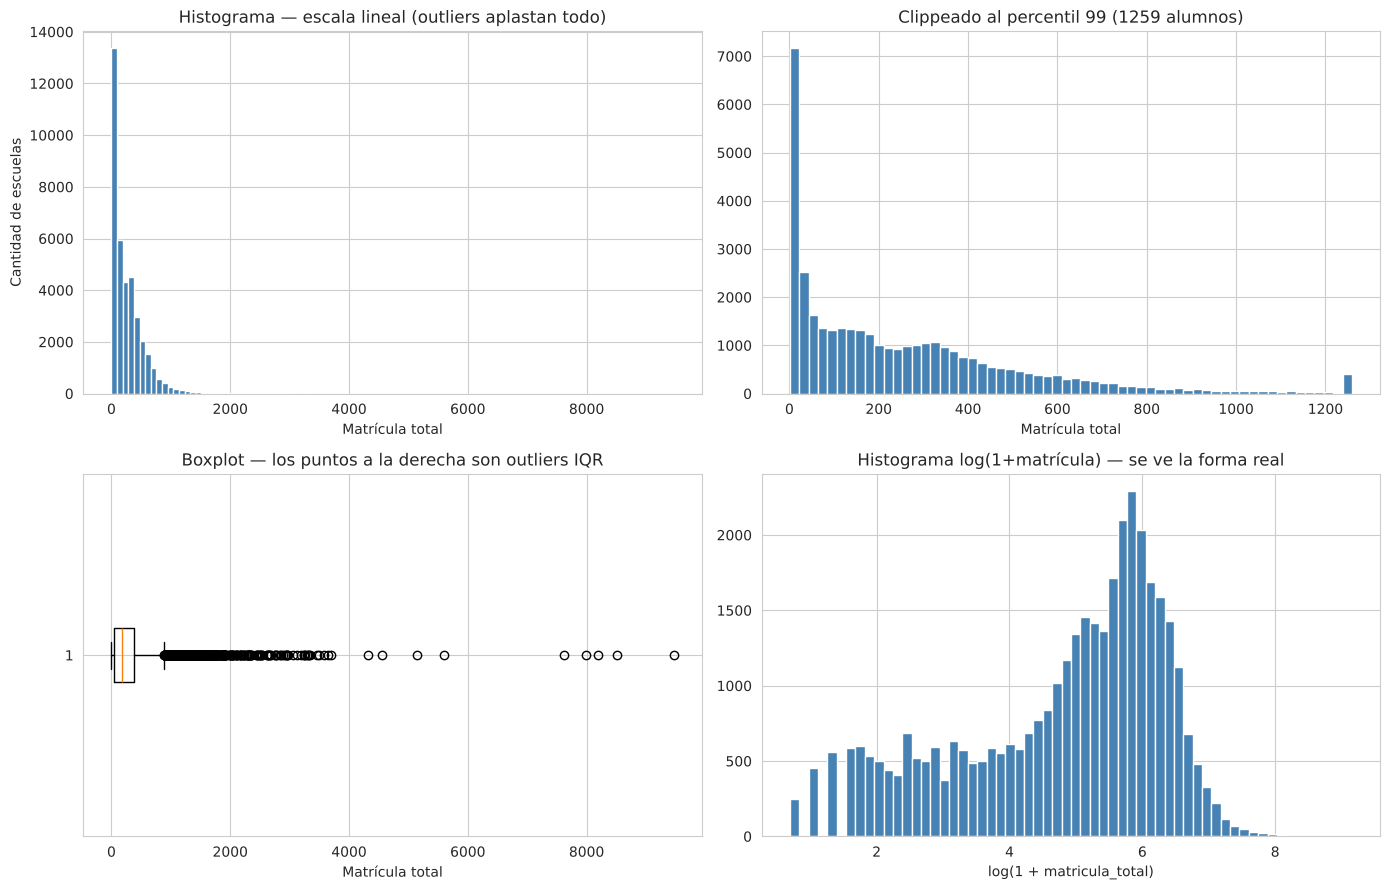

In [2]:
# Estadísticos descriptivos
print('Matrícula total por escuela:')
print(df['matricula_total'].describe(percentiles=[0.01, 0.25, 0.5, 0.75, 0.95, 0.99, 0.999]).round(1))

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

# Histograma normal (con outliers deforman todo)
axes[0,0].hist(df['matricula_total'], bins=100, color='steelblue', edgecolor='white')
axes[0,0].set_title('Histograma — escala lineal (outliers aplastan todo)')
axes[0,0].set_xlabel('Matrícula total')
axes[0,0].set_ylabel('Cantidad de escuelas')

# Histograma clippeado al percentil 99
cap = df['matricula_total'].quantile(0.99)
axes[0,1].hist(df['matricula_total'].clip(upper=cap), bins=60, color='steelblue', edgecolor='white')
axes[0,1].set_title(f'Clippeado al percentil 99 ({cap:.0f} alumnos)')
axes[0,1].set_xlabel('Matrícula total')

# Boxplot para ver outliers explícitamente
axes[1,0].boxplot(df['matricula_total'], vert=False)
axes[1,0].set_title('Boxplot — los puntos a la derecha son outliers IQR')
axes[1,0].set_xlabel('Matrícula total')

# Escala logarítmica revela la distribución verdadera
axes[1,1].hist(np.log1p(df['matricula_total']), bins=60, color='steelblue', edgecolor='white')
axes[1,1].set_title('Histograma log(1+matrícula) — se ve la forma real')
axes[1,1].set_xlabel('log(1 + matricula_total)')

plt.tight_layout()
plt.show()

## 2. Detección de outliers — tres métodos

In [3]:
# Método 1: Regla IQR
col = 'matricula_total'
Q1 = df[col].quantile(0.25)
Q3 = df[col].quantile(0.75)
IQR = Q3 - Q1
lower_iqr = Q1 - 1.5 * IQR
upper_iqr = Q3 + 1.5 * IQR

outliers_iqr = ((df[col] < lower_iqr) | (df[col] > upper_iqr))

print(f'=== Método 1: IQR ===')
print(f'  Q1 = {Q1:.1f}, Q3 = {Q3:.1f}, IQR = {IQR:.1f}')
print(f'  Límite inferior: {lower_iqr:.1f}')
print(f'  Límite superior: {upper_iqr:.1f}')
print(f'  Outliers detectados: {outliers_iqr.sum():,} ({100*outliers_iqr.mean():.1f}%)')

# Método 2: Z-score
mu    = df[col].mean()
sigma = df[col].std()
z = (df[col] - mu) / sigma
outliers_z = np.abs(z) > 3

print(f'\n=== Método 2: Z-score (|z| > 3) ===')
print(f'  Media: {mu:.1f}, Desvío: {sigma:.1f}')
print(f'  Outliers detectados: {outliers_z.sum():,} ({100*outliers_z.mean():.1f}%)')
print(f'  ⚠️ Z-score asume normalidad — con distribuciones sesgadas es menos confiable.')

# Método 3: Isolation Forest (multivariado)
features_iso = ['matricula_total', 'secciones_total', 'repetidores_total']
X_iso = df[features_iso].fillna(df[features_iso].median()).values

iso = IsolationForest(contamination=0.05, random_state=42)
outliers_iso = iso.fit_predict(X_iso) == -1

print(f'\n=== Método 3: Isolation Forest (multivariado) ===')
print(f'  Outliers detectados: {outliers_iso.sum():,} ({100*outliers_iso.mean():.1f}%)')
print(f'  Ventaja: detecta combinaciones anómalas, no solo extremos univariados.')

=== Método 1: IQR ===
  Q1 = 40.0, Q3 = 381.0, IQR = 341.0
  Límite inferior: -471.5
  Límite superior: 892.5
  Outliers detectados: 1,202 (3.2%)

=== Método 2: Z-score (|z| > 3) ===
  Media: 262.4, Desvío: 306.1
  Outliers detectados: 470 (1.3%)
  ⚠️ Z-score asume normalidad — con distribuciones sesgadas es menos confiable.



=== Método 3: Isolation Forest (multivariado) ===
  Outliers detectados: 1,880 (5.0%)
  Ventaja: detecta combinaciones anómalas, no solo extremos univariados.


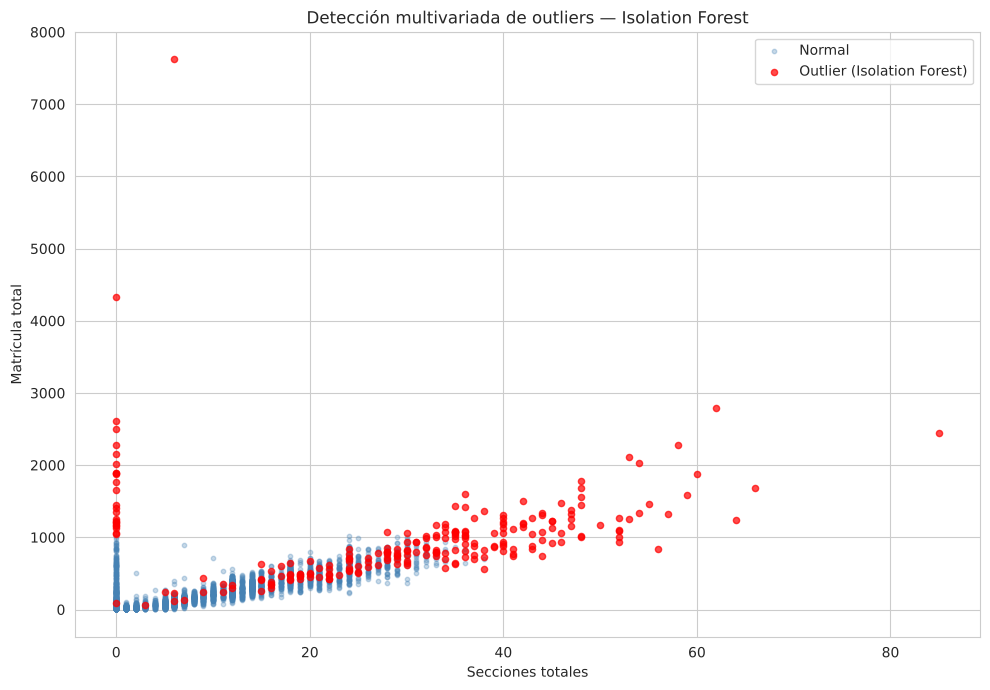

In [4]:
# Visualización de outliers en espacio bivariado
fig, ax = plt.subplots(figsize=(10, 7))

# Muestra de 5000 para velocidad de plot
sample = df.sample(n=min(5000, len(df)), random_state=42).index
X_plot = df.loc[sample, ['secciones_total', 'matricula_total']].values
mask_plot_iso = outliers_iso[df.index.isin(sample)]

# Indexado más robusto:
df_sample = df.loc[sample].copy()
df_sample['is_outlier_iso'] = outliers_iso[df.index.get_indexer(sample)]

ax.scatter(df_sample.loc[~df_sample['is_outlier_iso'], 'secciones_total'],
           df_sample.loc[~df_sample['is_outlier_iso'], 'matricula_total'],
           alpha=0.3, s=10, color='steelblue', label='Normal')
ax.scatter(df_sample.loc[df_sample['is_outlier_iso'], 'secciones_total'],
           df_sample.loc[df_sample['is_outlier_iso'], 'matricula_total'],
           alpha=0.7, s=20, color='red', label='Outlier (Isolation Forest)')
ax.set_xlabel('Secciones totales')
ax.set_ylabel('Matrícula total')
ax.set_title('Detección multivariada de outliers — Isolation Forest')
ax.legend()
plt.tight_layout()
plt.show()

## 3. Efecto de outliers en métricas de regresión

Tarea: predecir `repetidores_total` desde `matricula_total`, `secciones_total`, etc.

In [5]:
FEATURES = ['matricula_total', 'secciones_total', 'sector', 'ambito', 'provincia']
TARGET   = 'repetidores_total'
num_cols = ['matricula_total', 'secciones_total']
cat_cols = ['sector', 'ambito', 'provincia']

df_model = df.dropna(subset=[TARGET]).copy()
X = df_model[FEATURES].copy()
y = df_model[TARGET].values

# Identificar outliers del target
Q1_y = np.quantile(y, 0.25)
Q3_y = np.quantile(y, 0.75)
IQR_y = Q3_y - Q1_y
outliers_y = y > Q3_y + 1.5 * IQR_y
print(f'Outliers en el target (repetidores_total): {outliers_y.sum():,} ({100*outliers_y.mean():.1f}%)')

def evaluar(nombre, y_true, y_pred):
    mae  = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2   = r2_score(y_true, y_pred)
    print(f'  {nombre}')
    print(f'    MAE:       {mae:.3f}')
    print(f'    RMSE:      {rmse:.3f}')
    print(f'    RMSE/MAE:  {rmse/mae:.2f}  ← ratio diagnóstico')
    print(f'    R²:        {r2:.4f}')
    return mae, rmse, r2

Outliers en el target (repetidores_total): 4,408 (12.5%)


In [6]:
# Modelo lineal (sensible a outliers) vs. Random Forest (robusto)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

pre = ColumnTransformer([
    ('num', Pipeline([('imp', SimpleImputer(strategy='median')), ('sc', StandardScaler())]), num_cols),
    ('cat', Pipeline([('imp', SimpleImputer(strategy='most_frequent')), ('enc', OneHotEncoder(handle_unknown='ignore', sparse_output=False))]), cat_cols)
])

# Regresión lineal
pipe_lin = Pipeline([('pre', pre), ('model', LinearRegression())])
pipe_lin.fit(X_train, y_train)
y_pred_lin = pipe_lin.predict(X_test)

# Huber (robusto)
pipe_hub = Pipeline([('pre', pre), ('model', HuberRegressor(max_iter=200))])
pipe_hub.fit(X_train, y_train)
y_pred_hub = pipe_hub.predict(X_test)

# Random Forest
pipe_rf = Pipeline([('pre', pre), ('model', RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1))])
pipe_rf.fit(X_train, y_train)
y_pred_rf = pipe_rf.predict(X_test)

print('=== Con outliers presentes (el dataset tal como viene) ===\n')
mae_lin, rmse_lin, r2_lin = evaluar('Regresión Lineal', y_test, y_pred_lin)
mae_hub, rmse_hub, r2_hub = evaluar('Huber (robusto)',  y_test, y_pred_hub)
mae_rf,  rmse_rf,  r2_rf  = evaluar('Random Forest',    y_test, y_pred_rf)

=== Con outliers presentes (el dataset tal como viene) ===

  Regresión Lineal
    MAE:       10.534
    RMSE:      19.875
    RMSE/MAE:  1.89  ← ratio diagnóstico
    R²:        0.2831
  Huber (robusto)
    MAE:       9.395
    RMSE:      21.488
    RMSE/MAE:  2.29  ← ratio diagnóstico
    R²:        0.1621
  Random Forest
    MAE:       9.666
    RMSE:      20.471
    RMSE/MAE:  2.12  ← ratio diagnóstico
    R²:        0.2395


## 4. ¿Qué pasa si filtramos outliers?

In [7]:
# Filtrar outliers del target en train (NO en test — eso sería trampa)
Q1_train = np.quantile(y_train, 0.25)
Q3_train = np.quantile(y_train, 0.75)
IQR_train = Q3_train - Q1_train
mask_in = y_train <= Q3_train + 1.5 * IQR_train

X_train_clean = X_train.iloc[mask_in]
y_train_clean = y_train[mask_in]

print(f'Train original: {len(X_train):,}')
print(f'Train sin outliers del target: {len(X_train_clean):,} ({100*mask_in.mean():.1f}%)')
print()

# Reentrenar los 3 modelos
pipe_lin_c = Pipeline([('pre', pre), ('model', LinearRegression())])
pipe_lin_c.fit(X_train_clean, y_train_clean)
y_pred_lin_c = pipe_lin_c.predict(X_test)

pipe_rf_c = Pipeline([('pre', pre), ('model', RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1))])
pipe_rf_c.fit(X_train_clean, y_train_clean)
y_pred_rf_c = pipe_rf_c.predict(X_test)

print('=== SIN outliers en training ===\n')
mae_lin_c, rmse_lin_c, r2_lin_c = evaluar('Regresión Lineal', y_test, y_pred_lin_c)
mae_rf_c,  rmse_rf_c,  r2_rf_c  = evaluar('Random Forest',    y_test, y_pred_rf_c)

Train original: 28,135
Train sin outliers del target: 24,602 (87.4%)



=== SIN outliers en training ===

  Regresión Lineal
    MAE:       9.695
    RMSE:      23.134
    RMSE/MAE:  2.39  ← ratio diagnóstico
    R²:        0.0288
  Random Forest
    MAE:       9.310
    RMSE:      23.027
    RMSE/MAE:  2.47  ← ratio diagnóstico
    R²:        0.0377


## 5. Comparación final

Comparación global:
               modelo     MAE    RMSE  RMSE/MAE     R²
Lineal (con outliers) 10.5342 19.8751    1.8867 0.2831
Lineal (sin outliers)  9.6953 23.1340    2.3861 0.0288
                Huber  9.3953 21.4880    2.2871 0.1621
    RF (con outliers)  9.6665 20.4707    2.1177 0.2395
    RF (sin outliers)  9.3100 23.0271    2.4734 0.0377


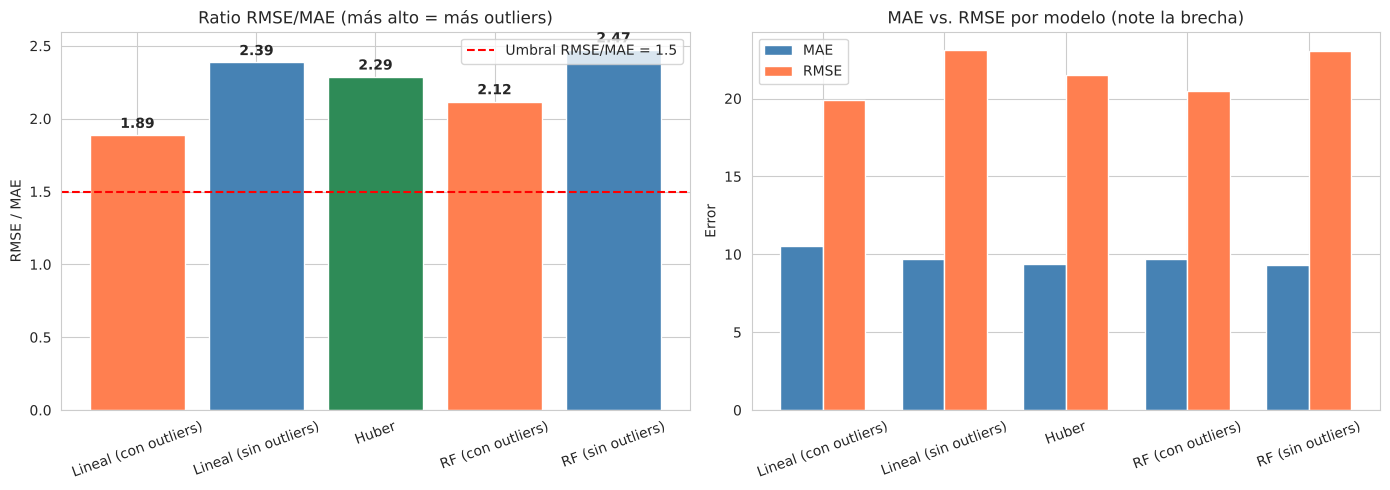

In [8]:
comparacion = pd.DataFrame({
    'modelo':     ['Lineal (con outliers)', 'Lineal (sin outliers)', 'Huber', 'RF (con outliers)', 'RF (sin outliers)'],
    'MAE':        [mae_lin,  mae_lin_c, mae_hub, mae_rf, mae_rf_c],
    'RMSE':       [rmse_lin, rmse_lin_c, rmse_hub, rmse_rf, rmse_rf_c],
    'RMSE/MAE':   [rmse_lin/mae_lin, rmse_lin_c/mae_lin_c, rmse_hub/mae_hub, rmse_rf/mae_rf, rmse_rf_c/mae_rf_c],
    'R²':         [r2_lin,   r2_lin_c, r2_hub, r2_rf, r2_rf_c],
}).round(4)

print('Comparación global:')
print(comparacion.to_string(index=False))

# Visualización del ratio RMSE/MAE
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

bars1 = axes[0].bar(comparacion['modelo'], comparacion['RMSE/MAE'],
                    color=['coral','steelblue','seagreen','coral','steelblue'], edgecolor='white')
axes[0].axhline(1.5, color='red', linestyle='--', label='Umbral RMSE/MAE = 1.5')
axes[0].set_title('Ratio RMSE/MAE (más alto = más outliers)')
axes[0].set_ylabel('RMSE / MAE')
axes[0].tick_params(axis='x', rotation=20)
axes[0].legend()
for bar, v in zip(bars1, comparacion['RMSE/MAE']):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.05,
                 f'{v:.2f}', ha='center', fontweight='bold')

x = np.arange(len(comparacion))
w = 0.35
axes[1].bar(x - w/2, comparacion['MAE'], w, label='MAE', color='steelblue')
axes[1].bar(x + w/2, comparacion['RMSE'], w, label='RMSE', color='coral')
axes[1].set_xticks(x)
axes[1].set_xticklabels(comparacion['modelo'], rotation=20)
axes[1].set_title('MAE vs. RMSE por modelo (note la brecha)')
axes[1].set_ylabel('Error')
axes[1].legend()

plt.tight_layout()
plt.show()

## 6. Interpretación — por qué RMSE/MAE es el indicador clave

| Modelo | RMSE/MAE | Diagnóstico |
|---|---|---|
| Lineal con outliers | alto | muy sensible, infla RMSE |
| Lineal sin outliers | bajo | errores uniformes |
| Huber | intermedio | robusto por diseño |
| Random Forest | moderado | algunos outliers mal predichos |

### ¿Cuándo RMSE/MAE indica problema?
- **< 1.25**: errores uniformes, todo bien
- **1.25 – 1.5**: algunos outliers, revisar
- **> 1.5**: outliers influyentes, tratamiento requerido
- **> 2.0**: outliers dominando, crítico

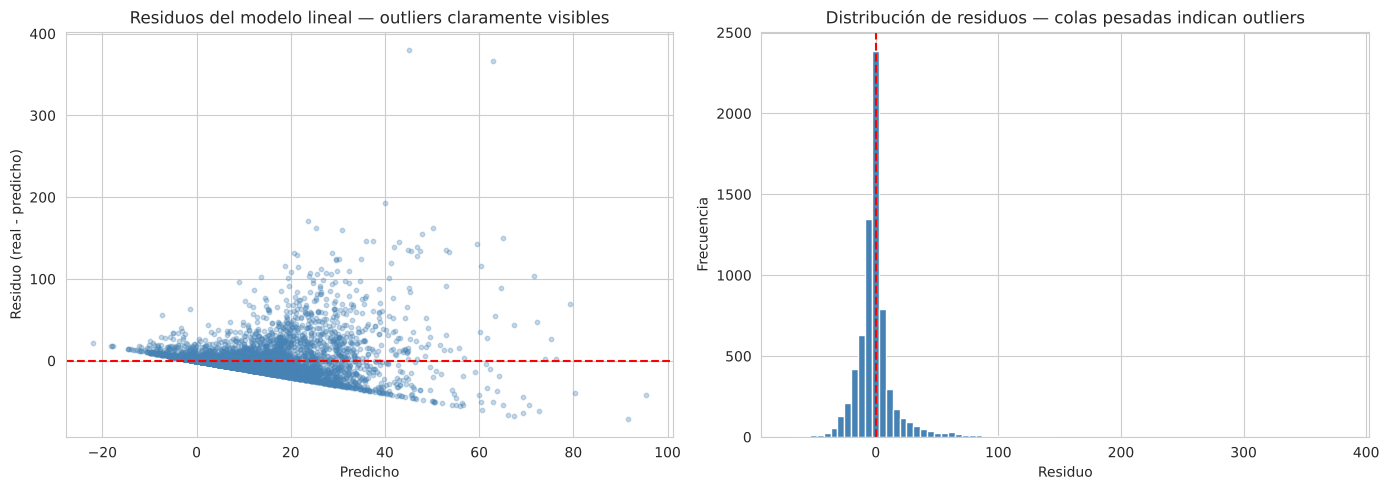

In [9]:
# Visualizar residuos del modelo lineal — los outliers saltan a la vista
residuos = y_test - y_pred_lin

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(y_pred_lin, residuos, alpha=0.3, s=10, color='steelblue')
axes[0].axhline(0, color='red', linestyle='--')
axes[0].set_xlabel('Predicho')
axes[0].set_ylabel('Residuo (real - predicho)')
axes[0].set_title('Residuos del modelo lineal — outliers claramente visibles')

axes[1].hist(residuos, bins=80, color='steelblue', edgecolor='white')
axes[1].axvline(0, color='red', linestyle='--')
axes[1].set_xlabel('Residuo')
axes[1].set_ylabel('Frecuencia')
axes[1].set_title('Distribución de residuos — colas pesadas indican outliers')

plt.tight_layout()
plt.show()

## 7. Resumen — dónde están los outliers y qué hacer

### Dónde encontrarlos
- **En features numéricas**: valores extremos (escuelas muy grandes o muy chicas)
- **En el target**: repetidores_total con valores extremos
- **Multivariados**: combinaciones inusuales (pocas secciones con muchos alumnos)

### Por qué importan
1. Un outlier infla **RMSE/MSE por el término cuadrático**
2. **Regresión lineal** desplaza coeficientes hacia el outlier
3. **K-Means** desplaza centroides
4. **R²** puede inflarse artificialmente
5. **Árboles** son más robustos pero no inmunes

### Cómo detectarlos
| Método | Cuándo usar | Limitación |
|---|---|---|
| IQR (1.5×IQR) | Rápido, datos sesgados | No multivariado |
| Z-score (>3) | Datos normales | Fracasa con asimetría |
| Isolation Forest | Multivariado, grande | Requiere tuning de contamination |
| LOF (Local Outlier Factor) | Densidad local | Lento con N grande |

### Cómo decidir qué hacer
1. **¿Es un error de medición?** (ej: edad = 300) → eliminar
2. **¿Es un valor real pero extremo?** (ej: escuela de 3000 alumnos) → preservar
3. **¿Se puede transformar?** (log, Box-Cox) → suele resolver
4. **¿El modelo es sensible?** → cambiar a robusto (Huber, Random Forest)
5. **¿La métrica apropiada es otra?** → usar MAE en vez de RMSE

### Regla operativa
> **Calcular siempre RMSE/MAE. Si supera 1.5, investigar outliers explícitamente.**
>
> **No eliminar outliers sin entender su causa.** En datos reales suelen ser informativos,
> no "basura" — una escuela con 3000 alumnos NO es un error, es un dato valioso.